# Issue1: Validate Databento Data Availability and Timestamp Comparability

Use Python 3.10+ and your own Databento API key. Missing dependencies are installed in the active kernel. Zero-cost estimates proceed automatically; paid estimates require confirmation within the configured budget. No credentials are saved.


In [ ]:
import sys, subprocess, importlib.util, importlib.metadata
if sys.version_info < (3, 10):
    raise RuntimeError('Use a Python 3.10 or newer notebook kernel.')
packages = {'numpy': 'numpy>=1.23', 'pandas': 'pandas>=1.5',
            'matplotlib': 'matplotlib>=3.5', 'IPython': 'ipython>=8',
            'databento': 'databento>=0.40,<1', 'tzdata': 'tzdata'}
missing = [requirement for module, requirement in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    print('Installing:', ', '.join(missing))
    subprocess.run([sys.executable, '-m', 'pip', 'install', *missing], check=True)
    importlib.invalidate_caches()
else:
    print('Required packages are installed.')


Required packages are installed.


In [ ]:
import os, json, hashlib, platform, importlib.metadata, getpass, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

DATASET = 'GLBX.MDP3'
SAMPLE_DATE = '2026-10-08'  # Choose a trading date within the range returned for the account.
START_LOCAL = '09:00:00'
TIMEZONE = 'America/Chicago'
DURATION_MINUTES = 10
PADDING_SECONDS = 2
N_STRIKES = 3             # Small sample: three strikes near ATM, calls and puts.
WINDOW_US = 10_000        # Matching window: +/-10 ms.
MAX_PRE_QUOTE_AGE_US = 1_000_000
AUTO_APPROVE_ZERO_COST = True
AUTO_APPROVE_PAID = False
BUDGET_USD = 3.0          # Estimated download budget for this session.
CORE_START = pd.Timestamp(f'{SAMPLE_DATE} {START_LOCAL}', tz=TIMEZONE).tz_convert('UTC')
CORE_END = CORE_START + pd.Timedelta(minutes=DURATION_MINUTES)
REQUEST_START = CORE_START - pd.Timedelta(seconds=PADDING_SECONDS)
REQUEST_END = CORE_END + pd.Timedelta(seconds=PADDING_SECONDS)
# Request definitions from UTC midnight up to the sample start.
DEF_START = CORE_START.normalize()
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
CACHE = ROOT / 'data' / 'raw' / 'issue1'
OUT = ROOT / 'reports' / 'issue1_report' / SAMPLE_DATE
CACHE.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)
print('Sample UTC:', CORE_START, 'to', CORE_END)
print('Repository root:', ROOT)

# Thresholds flag concerns for review; they are not synchronization error bounds.
MAX_MEDIAN_RECEPTION_GAP_US = 1_000
MAX_OVERLAP_FRACTION = .25
MIN_ISOLATED_PAIRS = 30


Sample UTC: 2026-10-08 14:00:00+00:00 to 2026-10-08 14:10:00+00:00
Repository root: /Users/christina/Desktop/Futures


## 1. Timestamp and quote-update functions

Within each contract, retain the final quote state at each event timestamp before computing midpoint and BBO changes. Invalid final states reset the comparison. Nanosecond differences are retained before conversion to microseconds.

Signed-nearest matching and strict-first-after waiting times are descriptive diagnostics. Censored forward matches have unknown overlap status. Event and reception clocks use their own next-futures-event timestamps.


In [3]:
def timestamp_frame(frame):
    d = frame.copy()
    if 'ts_recv' not in d.columns and d.index.name == 'ts_recv':
        d = d.reset_index()
    for c in ('ts_event', 'ts_recv'):
        if c not in d:
            raise ValueError(f'Missing required field: {c}')
        d[c] = pd.to_datetime(d[c], utc=True, errors='coerce').astype('datetime64[ns, UTC]')
    if 'instrument_id' not in d:
        raise ValueError('instrument_id is required')
    d['_arrival'] = np.arange(len(d))
    return d


def timestamp_quality(frame, label):
    d = timestamp_frame(frame)
    rows = []
    for iid, g in d.groupby('instrument_id', sort=False):
        lag = (g.ts_recv - g.ts_event).dt.total_seconds() * 1e6
        flags = pd.to_numeric(g.get('flags', pd.Series(0, index=g.index)), errors='coerce').fillna(0).astype('int64')
        rows.append(dict(market=label, instrument_id=int(iid), records=len(g),
            missing_event=int(g.ts_event.isna().sum()), missing_recv=int(g.ts_recv.isna().sum()),
            event_backsteps=int((g.ts_event.diff() < pd.Timedelta(0)).sum()),
            recv_backsteps=int((g.ts_recv.diff() < pd.Timedelta(0)).sum()),
            duplicate_event_times=int(g.ts_event.duplicated().sum()),
            bad_recv_or_snapshot=int(((flags & 40) != 0).sum()),
            negative_recv_event=int((lag < 0).sum()),
            recv_event_median_us=lag.median(), recv_event_p95_us=lag.quantile(.95),
            recv_event_p99_us=lag.quantile(.99)))
    return pd.DataFrame(rows)


def bbo_changes(frame):
    d = timestamp_frame(frame)
    cols = ['bid_px_00', 'ask_px_00', 'bid_sz_00', 'ask_sz_00']
    if not set(cols).issubset(d.columns):
        raise ValueError(f'Missing BBO fields: {set(cols) - set(d.columns)}')
    for c in cols:
        d[c] = pd.to_numeric(d[c], errors='coerce')
    # to_df uses pretty floating prices; reject undefined/huge price sentinels.
    flags = pd.to_numeric(d.get('flags', pd.Series(0, index=d.index)), errors='coerce').fillna(0).astype('int64')
    valid = (d.ts_event.notna() & d.ts_recv.notna() & (flags & 40).eq(0)
        & d.bid_px_00.gt(0) & d.ask_px_00.gt(0)
        & d.bid_px_00.lt(1e8) & d.ask_px_00.lt(1e8)
        & d.bid_px_00.le(d.ask_px_00) & d.bid_sz_00.gt(0) & d.ask_sz_00.gt(0))
    outputs=[]
    for _, g in d.groupby('instrument_id', sort=False):
        # Preserve arrival order for changes, including reset after invalid state.
        ok = valid.loc[g.index]
        prev = g[cols].shift()
        change = g[cols].ne(prev).any(axis=1) & ok & ok.shift(fill_value=False)
        g = g.loc[change].copy()
        g['mid'] = (g.bid_px_00 + g.ask_px_00)/2
        # Delta needs valid prior state from original records, not only changed rows.
        original = d.loc[d.instrument_id == (g.instrument_id.iloc[0] if len(g) else -1)]
        if len(g):
            original_mid = (original.bid_px_00 + original.ask_px_00)/2
            g['delta_mid'] = original_mid.diff().reindex(g.index)
            outputs.append(g)
    if not outputs:
        return d.iloc[:0].assign(mid=pd.Series(dtype=float), delta_mid=pd.Series(dtype=float))
    return (pd.concat(outputs).sort_values(['ts_event', '_arrival'], kind='stable')
        .drop_duplicates(['instrument_id', 'ts_event'], keep='last').reset_index(drop=True))


def align_updates(events, updates, time_col='ts_event', window_us=10_000, max_age_us=1_000_000):
    """Per-contract nearest signed / strict forward update; no causal labels."""
    rows=[]
    w = int(window_us * 1000)
    age_limit = int(max_age_us * 1000)
    for iid, g in updates.groupby('instrument_id'):
        g = g.dropna(subset=[time_col]).sort_values([time_col, '_arrival'], kind='stable')
        g = g.drop_duplicates(time_col, keep='last')
        t = g[time_col].astype('int64').to_numpy()
        if not len(t):
            continue
        for _, e in events.iterrows():
            t0 = int(e[time_col].value)
            pos = int(np.searchsorted(t, t0, side='left'))
            before = pos - 1
            # Strict forward; ties reported separately.
            after = int(np.searchsorted(t, t0, side='right'))
            candidates = [j for j in (before, pos) if 0 <= j < len(t)]
            near = min(candidates, key=lambda j: (abs(int(t[j])-t0), int(t[j])))
            offset = int(t[near])-t0
            forward = int(t[after])-t0 if after < len(t) else None
            pre_age = t0-int(t[before]) if before >= 0 else None
            pre_ok = pre_age is not None and pre_age <= age_limit
            next_t = e.get('next_event_time', pd.NaT)
            contaminated = (forward is not None and pd.notna(next_t)
                and t0 + forward >= int(next_t.value))
            rows.append(dict(event_id=int(e.event_id), instrument_id=int(iid),
                t0=e[time_col], nearest_us=offset/1000 if abs(offset)<=w else np.nan,
                first_after_us=forward/1000 if forward is not None and forward<=w else np.nan,
                simultaneous=bool(pos<len(t) and int(t[pos])==t0),
                pre_quote_age_us=pre_age/1000 if pre_age is not None else np.nan,
                eligible_pre_state=bool(pre_ok), censored=forward is None or forward>w,
                another_futures_move_before_update=bool(contaminated)))
    return pd.DataFrame(rows)


def offset_summary(aligned):
    rows=[]
    if aligned.empty:
        return pd.DataFrame()
    for iid, g in aligned.groupby('instrument_id'):
        x=g.nearest_us.dropna(); f=g.first_after_us.dropna()
        rows.append(dict(instrument_id=int(iid), event_pairs=len(g),
            eligible_pre_state=int(g.eligible_pre_state.sum()), nearest_matched=len(x),
            negative_nearest_fraction=float((x<0).mean()) if len(x) else np.nan,
            simultaneous_fraction=float(g.simultaneous.mean()),
            nearest_median_us=x.median(), nearest_p05_us=x.quantile(.05),
            nearest_p95_us=x.quantile(.95), forward_matched=len(f),
            first_after_median_us=f.median(), first_after_p95_us=f.quantile(.95),
            right_censored_fraction=float(g.censored.mean()),
            contaminated_fraction=float(g.another_futures_move_before_update.mean())))
    return pd.DataFrame(rows)


legacy_bbo_changes = bbo_changes

def bbo_changes(frame):
    """Compare final quote states at distinct event timestamps, including resets."""
    d = timestamp_frame(frame)
    cols = ['bid_px_00', 'ask_px_00', 'bid_sz_00', 'ask_sz_00']
    if not set(cols).issubset(d.columns):
        raise ValueError('Required BBO fields are missing')
    for c in cols:
        d[c] = pd.to_numeric(d[c], errors='coerce')
    # Collapse raw states BEFORE calculating changes. A size update at the same
    # timestamp must not erase an earlier price move. Invalid final states reset
    # the comparison rather than disappearing from the history.
    d = (d.dropna(subset=['ts_event'])
         .sort_values(['instrument_id', 'ts_event', '_arrival'], kind='stable')
         .drop_duplicates(['instrument_id', 'ts_event'], keep='last'))
    outputs = []
    for _, g in d.groupby('instrument_id', sort=False):
        flags = pd.to_numeric(g.get('flags', pd.Series(0,index=g.index)), errors='coerce').fillna(0).astype('int64')
        valid = (g.ts_recv.notna() & (flags & 40).eq(0)
            & g.bid_px_00.gt(0) & g.ask_px_00.gt(0)
            & g.bid_px_00.lt(1e8) & g.ask_px_00.lt(1e8)
            & g.bid_px_00.le(g.ask_px_00) & g.bid_sz_00.gt(0) & g.ask_sz_00.gt(0))
        changed = g[cols].ne(g[cols].shift()).any(axis=1)
        eligible = valid & valid.shift(fill_value=False)
        g = g.copy()
        g['mid'] = (g.bid_px_00 + g.ask_px_00)/2
        g['delta_mid'] = g.mid.diff()
        outputs.append(g.loc[eligible & changed])
    if not outputs:
        return d.iloc[:0].assign(mid=pd.Series(dtype=float),delta_mid=pd.Series(dtype=float))
    return pd.concat(outputs).sort_values(['ts_event','_arrival'],kind='stable').reset_index(drop=True)


def align_updates(events, updates, time_col='ts_event', window_us=10_000, max_age_us=1_000_000):
    """Vectorized signed-nearest and strict-forward matching, separately by contract."""
    w = int(window_us*1000); age_limit = int(max_age_us*1000)
    results=[]
    if events.empty or updates.empty:
        return pd.DataFrame()
    e=events.dropna(subset=[time_col]).copy()
    event_ns=e[time_col].astype('datetime64[ns, UTC]').astype('int64').to_numpy()
    # Last core event still needs the next event from the padded data, if present.
    next_col='next_event_time' if time_col=='ts_event' else 'next_recv_time'
    next_values=e.get(next_col,pd.Series(pd.NaT,index=e.index,dtype='datetime64[ns, UTC]'))
    next_ns=pd.to_datetime(next_values,utc=True).astype('datetime64[ns, UTC]').astype('int64').to_numpy()
    has_next=pd.notna(next_values).to_numpy()
    for iid,g in updates.groupby('instrument_id'):
        g=g.dropna(subset=[time_col]).sort_values([time_col,'_arrival'],kind='stable').drop_duplicates(time_col,keep='last')
        t=g[time_col].astype('datetime64[ns, UTC]').astype('int64').to_numpy()
        if not len(t):continue
        pos=np.searchsorted(t,event_ns,side='left')
        before=pos-1; after=np.searchsorted(t,event_ns,side='right')
        left=t[np.clip(before,0,len(t)-1)]-event_ns
        right=t[np.clip(pos,0,len(t)-1)]-event_ns
        left_dist=np.where(before>=0,np.abs(left),np.iinfo(np.int64).max)
        right_dist=np.where(pos<len(t),np.abs(right),np.iinfo(np.int64).max)
        nearest=np.where(left_dist<=right_dist,left,right)
        forward=t[np.clip(after,0,len(t)-1)]-event_ns
        forward_ok=(after<len(t))&(forward<=w)
        pre_age=event_ns-t[np.clip(before,0,len(t)-1)]
        # Censored cases do not get a reaction-contamination classification.
        overlap=np.full(len(e),np.nan)
        overlap[forward_ok]=(has_next & (event_ns+forward>=next_ns))[forward_ok].astype(float)
        results.append(pd.DataFrame(dict(event_id=e.event_id.to_numpy(),instrument_id=int(iid),
            t0=e[time_col].to_numpy(),nearest_us=np.where(np.abs(nearest)<=w,nearest/1000,np.nan),
            first_after_us=np.where(forward_ok,forward/1000,np.nan),
            simultaneous=(pos<len(t))&(t[np.clip(pos,0,len(t)-1)]==event_ns),
            pre_quote_age_us=np.where(before>=0,pre_age/1000,np.nan),
            eligible_pre_state=(before>=0)&(pre_age<=age_limit),
            censored=~forward_ok,another_futures_move_before_update=overlap)))
    return pd.concat(results,ignore_index=True) if results else pd.DataFrame()


def isolated_events(all_events, window_us):
    """No other futures midpoint event in the symmetric diagnostic window."""
    g=all_events.sort_values('ts_event').copy()
    prev=g.ts_event.diff().dt.total_seconds()*1e6
    nxt=(g.ts_event.shift(-1)-g.ts_event).dt.total_seconds()*1e6
    # Endpoints are excluded because their neighboring event is unknown.
    return g[(prev>window_us)&(nxt>window_us)
             &(g.ts_event>=CORE_START)&(g.ts_event<CORE_END)]


def directional_diagnostics(events,updates,option_definitions,window_us):
    """Signed offsets to direction-consistent midpoint changes, not causal responses."""
    results=[]
    cp=option_definitions.set_index('instrument_id').instrument_class.to_dict()
    for iid,g in updates.groupby('instrument_id'):
        option_sign=1 if cp.get(iid)=='C' else -1 if cp.get(iid)=='P' else None
        if option_sign is None:continue
        for move_sign in [-1,1]:
            ev=events[events.delta_mid*move_sign>0]
            candidates=g[g.delta_mid*(move_sign*option_sign)>0]
            a=align_updates(ev,candidates,window_us=window_us,max_age_us=MAX_PRE_QUOTE_AGE_US)
            if not a.empty:
                a['expected_option_direction']=move_sign*option_sign
                results.append(a)
    return pd.concat(results,ignore_index=True) if results else pd.DataFrame()


## 2. Synthetic and regression tests

Test both the original matching cases and the same-timestamp price/size bug, invalid final states, reception-time overlap, and censored overlap status. Passing tests checks the implementation; sample findings still require a real run.


In [4]:
def run_synthetic_tests():
    base=pd.Timestamp('2026-10-08T14:00:00Z')
    def make(offsets, iid=2):
        times=[base+pd.Timedelta(int(x), unit='ns') for x in offsets]
        return pd.DataFrame({'instrument_id':iid, 'ts_event':times,
            'ts_recv':[t+pd.Timedelta(100, unit='ns') for t in times],
            '_arrival':range(len(times))})
    events=pd.DataFrame({'event_id':[0], 'ts_event':[base], 'ts_recv':[base]})
    a=align_updates(events, make([-1_000_000,200_000]))
    assert a.nearest_us.iloc[0]==200 and a.first_after_us.iloc[0]==200
    a=align_updates(events, make([-100_000,300_000]))
    assert a.nearest_us.iloc[0]==-100 and a.first_after_us.iloc[0]==300
    a=align_updates(events, make([-100_000,123]))
    assert a.first_after_us.iloc[0]==.123
    a=align_updates(events, make([-100_000,20_000_000]), window_us=10_000)
    assert a.censored.iloc[0] and pd.isna(a.first_after_us.iloc[0])
    a=align_updates(events, make([200_000,-1_000_000]))
    assert a.first_after_us.iloc[0]==200
    a=align_updates(events, make([-100_000,0,300_000]))
    assert a.simultaneous.iloc[0] and a.nearest_us.iloc[0]==0 and a.first_after_us.iloc[0]==300
    a=align_updates(events,pd.concat([make([-100_000,200_000],2),make([-100_000,400_000],3)]))
    assert dict(zip(a.instrument_id,a.first_after_us))=={2:200,3:400}
    a=align_updates(events,make([200_000]))
    assert not a.eligible_pre_state.iloc[0]
    q=make([0,100_000,200_000]); q.loc[1,'ts_event']=pd.NaT
    assert timestamp_quality(q,'test').missing_event.iloc[0]==1
    q=make([0,100_000,200_000]); q['bid_px_00']=[10.,10.,10.25]
    q['ask_px_00']=[10.25,10.25,10.5]; q['bid_sz_00']=1; q['ask_sz_00']=1
    assert len(bbo_changes(q))==1
    # Invalid quote resets the state; do not manufacture a move across the gap.
    q.loc[1,'bid_sz_00']=0
    assert bbo_changes(q).empty
    print('11 synthetic scenarios passed.')
    return 11

SYNTHETIC_TESTS_PASSED=run_synthetic_tests()


def run_regression_tests():
    b=pd.Timestamp('2026-10-08T14:00:00Z')
    q=pd.DataFrame({'instrument_id':[1,1,1],
        'ts_event':[b,b+pd.Timedelta(1,'ms'),b+pd.Timedelta(1,'ms')],
        'ts_recv':[b+pd.Timedelta(100,'us'),b+pd.Timedelta(1100,'us'),b+pd.Timedelta(1200,'us')],
        'bid_px_00':[100,100.25,100.25],'ask_px_00':[100.25,100.5,100.5],
        'bid_sz_00':[1,1,2],'ask_sz_00':[1,1,1]})
    assert bbo_changes(q).delta_mid.iloc[0]==.25
    q.loc[2,'bid_sz_00']=0
    assert bbo_changes(q).empty
    e=pd.DataFrame({'event_id':[0],'ts_event':[b],'ts_recv':[b],
        'next_event_time':[b+pd.Timedelta(100,'us')],'next_recv_time':[b+pd.Timedelta(100,'us')]})
    u=pd.DataFrame({'instrument_id':[2,2], 'ts_event':[b-pd.Timedelta(1,'ms'),b+pd.Timedelta(200,'us')],
        'ts_recv':[b-pd.Timedelta(1,'ms'),b+pd.Timedelta(200,'us')], '_arrival':[0,1]})
    assert align_updates(e,u,time_col='ts_recv').another_futures_move_before_update.iloc[0]==1
    a=align_updates(e,u,window_us=50)
    assert a.censored.iloc[0] and pd.isna(a.another_futures_move_before_update.iloc[0])
    print('4 additional regression scenarios passed.')
    return 4
SYNTHETIC_TESTS_PASSED += run_regression_tests()


def run_directional_tests():
    b=pd.Timestamp('2026-10-08T14:00:00Z')
    times=[b+pd.Timedelta(x,'ms') for x in [0,30,60]]
    e=pd.DataFrame({'event_id':[0,1,2],'ts_event':times,'ts_recv':times,'delta_mid':[.25,.25,.25]})
    iso=isolated_events(e,10_000)
    assert iso.event_id.tolist()==[1]
    u=pd.DataFrame({'instrument_id':[2,2,2],
        'ts_event':[times[1]-pd.Timedelta(100,'us'),times[1]+pd.Timedelta(200,'us'),times[1]+pd.Timedelta(300,'us')],
        'ts_recv':[times[1]-pd.Timedelta(100,'us'),times[1]+pd.Timedelta(200,'us'),times[1]+pd.Timedelta(300,'us')],
        '_arrival':[0,1,2],'delta_mid':[.1,-.1,.1]})
    definitions=pd.DataFrame({'instrument_id':[2],'instrument_class':['C']})
    a=directional_diagnostics(iso,u,definitions,10_000)
    assert a.nearest_us.iloc[0]==-100 and a.first_after_us.iloc[0]==300
    print('2 isolation/directional scenarios passed.')
    return 2
SYNTHETIC_TESTS_PASSED += run_directional_tests()


11 synthetic scenarios passed.
4 additional regression scenarios passed.
2 isolation/directional scenarios passed.


## 3. Authentication and downloads

Use your own `DATABENTO_API_KEY` environment variable or the hidden prompt. Credentials are never written into the notebook or its reports.

Identical requests use cached DBN files. Uncached requests are estimated first. Zero-cost estimates are accepted automatically; paid requests ask for confirmation unless `AUTO_APPROVE_PAID` was explicitly enabled. All requests remain subject to the cumulative estimate budget. Cost estimates are not billing guarantees.

For unattended execution, provide the environment variable. Positive-cost requests also require `AUTO_APPROVE_PAID=True`; leave it disabled if you want to review each estimate. The cache is local, so another team member's first run needs their own data access.


In [5]:
import databento as db
import inspect
key = os.environ.get('DATABENTO_API_KEY', '').strip()
if not key:
    key = getpass.getpass('Enter your Databento API key (hidden): ')
if not key.strip():
    raise ValueError('No API key supplied')
client = db.Historical(key.strip())
_SECRET = key.strip()
del key
REQUEST_LOG=[]
ESTIMATED_SESSION_COST=0.0

def safe_error(exc):
    text=str(exc).replace(_SECRET, '[REDACTED]')
    return re.sub(r'db-[A-Za-z0-9_-]+', '[REDACTED]', text)[:1500]

def api_call(fn, **kwargs):
    try:
        return fn(**kwargs)
    except Exception as exc:
        raise RuntimeError(f'{type(exc).__name__}: {safe_error(exc)}') from None

def store_frame(store):
    # Databento versions use either price_type or pretty_px for float conversion.
    signature = inspect.signature(store.to_df).parameters
    kwargs = {'pretty_ts': True} if 'pretty_ts' in signature else {}
    if 'price_type' in signature:
        kwargs['price_type'] = 'float'
    elif 'pretty_px' in signature:
        kwargs['pretty_px'] = True
    frame = store.to_df(**kwargs)
    return frame.reset_index() if frame.index.name == 'ts_recv' and 'ts_recv' not in frame else frame.reset_index(drop=True)

def download_cached(schema, symbols, start, end, stype_in='raw_symbol'):
    global ESTIMATED_SESSION_COST
    params=dict(dataset=DATASET,schema=schema,symbols=symbols,
                start=pd.Timestamp(start).isoformat(),end=pd.Timestamp(end).isoformat(),stype_in=stype_in)
    token=hashlib.sha256(json.dumps(params,sort_keys=True).encode()).hexdigest()[:20]
    path=CACHE/f'{schema}_{token}.dbn'
    if path.exists():
        REQUEST_LOG.append(dict(**params, cached=True, estimated_cost_usd=None))
        return store_frame(db.DBNStore.from_file(path))
    estimate=float(api_call(client.metadata.get_cost, **params))
    if not np.isfinite(estimate) or estimate<0:
        raise RuntimeError('Invalid cost estimate; request stopped')
    proposed=ESTIMATED_SESSION_COST+estimate
    print(f'{schema}: {len(symbols) if isinstance(symbols,list) else symbols}; estimated ${estimate:.4f}; session ${proposed:.4f}')
    if proposed>BUDGET_USD:
        raise RuntimeError('Estimated budget exceeded. Reduce scope or deliberately edit BUDGET_USD.')
    approved = (estimate == 0 and AUTO_APPROVE_ZERO_COST) or AUTO_APPROVE_PAID
    if not approved:
        try:
            approved = input('Type DOWNLOAD to accept this estimate: ').strip() == 'DOWNLOAD'
        except (EOFError, OSError):
            raise RuntimeError('Paid request needs confirmation. For unattended runs, explicitly set AUTO_APPROVE_PAID=True within your budget.') from None
    if not approved:
        raise RuntimeError('Download cancelled')
    # Reserve the estimate even if request subsequently fails, to avoid hidden retries.
    ESTIMATED_SESSION_COST=proposed
    store=api_call(client.timeseries.get_range, **params)
    tmp=path.with_suffix('.tmp.dbn')
    store.to_file(tmp)
    tmp.replace(path)
    REQUEST_LOG.append(dict(**params,cached=False,estimated_cost_usd=estimate))
    return store_frame(store)


## 4. Historical coverage

Save the range returned for the current API key, including any schema-specific ranges for `mbp-1` and `definition`. This provides the initial availability check. Successful sample downloads provide contract-level evidence for the selected date; the metadata range alone does not establish that every ES contract has records throughout the range or that all requests are free under the course license.


In [6]:
DATA_RANGE=api_call(client.metadata.get_dataset_range,dataset=DATASET)
print(json.dumps(DATA_RANGE,indent=2,default=str))
SCHEMAS=api_call(client.metadata.list_schemas,dataset=DATASET)
print('Available schemas:',SCHEMAS)
if 'mbp-1' not in SCHEMAS or 'definition' not in SCHEMAS:
    raise RuntimeError('Required schemas are unavailable')
for schema, start, end in [('mbp-1',REQUEST_START,REQUEST_END),('definition',DEF_START,CORE_START)]:
    coverage=DATA_RANGE.get('schema',{}).get(schema,DATA_RANGE)
    if not (pd.Timestamp(coverage['start'])<=start and end<=pd.Timestamp(coverage['end'])):
        raise RuntimeError(f'{schema}: selected date lies outside metadata range; edit SAMPLE_DATE and rerun configuration')
(OUT/'available_range.json').write_text(json.dumps(DATA_RANGE,indent=2,default=str))


{
  "start": "2010-06-06T00:00:00.000000000Z",
  "end": "2026-10-11T13:08:20.817591000Z",
  "schema": {
    "mbo": {
      "start": "2017-05-21T00:00:00.000000000Z",
      "end": "2026-10-11T13:08:20.817591000Z"
    },
    "mbp-1": {
      "start": "2010-06-06T00:00:00.000000000Z",
      "end": "2026-10-11T13:08:20.817591000Z"
    },
    "mbp-10": {
      "start": "2010-06-06T00:00:00.000000000Z",
      "end": "2026-10-11T13:08:20.817591000Z"
    },
    "tbbo": {
      "start": "2010-06-06T00:00:00.000000000Z",
      "end": "2026-10-11T13:08:20.817591000Z"
    },
    "trades": {
      "start": "2010-06-06T00:00:00.000000000Z",
      "end": "2026-10-11T13:08:20.817591000Z"
    },
    "bbo-1s": {
      "start": "2010-06-06T00:00:00.000000000Z",
      "end": "2026-10-11T13:08:20.817591000Z"
    },
    "bbo-1m": {
      "start": "2010-06-06T00:00:00.000000000Z",
      "end": "2026-10-11T13:08:20.817591000Z"
    },
    "ohlcv-1s": {
      "start": "2010-06-06T00:00:00.000000000Z",
      "en

2126

## 5. Futures and 0DTE option selection

Retrieve `ALL_SYMBOLS` instrument definitions and identify outright ES futures. Link options through `underlying` or `underlying_id`, which also captures daily and weekly options listed under roots other than `ES`.

For this sample, the front-month future is the nearest unexpired outright contract. This is a calendar-based choice; selecting the most actively traded contract during a roll belongs in the broader instrument-selection work. The candidate futures are displayed for review.

Options must expire on the sample date in Chicago time and remain unexpired through the end of the window. If definitions or eligible options are missing, the notebook stops so the date, lookback, and contract mapping can be checked.


In [7]:
def normalize_definitions(df, asof):
    d=timestamp_frame(df)
    d=d[d.ts_recv<=asof].sort_values(['ts_recv','_arrival'],kind='stable')
    d=d.drop_duplicates('instrument_id',keep='last').copy()
    for c in ['raw_symbol','asset','instrument_class','underlying']:
        if c in d:
            d[c]=d[c].map(lambda v: v.decode() if isinstance(v,bytes) else str(v)).str.strip()
    d['expiration']=pd.to_datetime(d.expiration,utc=True,errors='coerce')
    # Drop latest definitions that explicitly delete an instrument.
    if 'security_update_action' in d:
        d=d[~d.security_update_action.astype(str).isin(['D','Delete'])]
    return d

DEFINITIONS=download_cached('definition','ALL_SYMBOLS',DEF_START,CORE_START)
DEFS=normalize_definitions(DEFINITIONS,CORE_START)
FUTURES_CANDIDATES=DEFS[(DEFS.asset=='ES') & (DEFS.instrument_class=='F') & (DEFS.expiration>CORE_END)].sort_values('expiration')
if FUTURES_CANDIDATES.empty:
    raise RuntimeError('No ES futures definitions found. Try another date or extend definitions lookback; do not infer no entitlement.')
FUTURE=FUTURES_CANDIDATES.iloc[0]
FUTURE_SYMBOL=FUTURE.raw_symbol
FUTURE_ID=int(FUTURE.instrument_id)
underlying_match=pd.Series(False,index=DEFS.index)
if 'underlying' in DEFS:
    underlying_match |= DEFS.underlying.eq(FUTURE_SYMBOL)
if 'underlying_id' in DEFS:
    underlying_match |= pd.to_numeric(DEFS.underlying_id,errors='coerce').eq(FUTURE_ID)
OPTIONS_CANDIDATES=DEFS[DEFS.instrument_class.isin(['C','P']) & underlying_match].copy()
expiry_dates=OPTIONS_CANDIDATES.expiration.dt.tz_convert(TIMEZONE).dt.date
OPTIONS_CANDIDATES=OPTIONS_CANDIDATES[(expiry_dates==pd.Timestamp(SAMPLE_DATE).date()) & (OPTIONS_CANDIDATES.expiration>CORE_END)]
if OPTIONS_CANDIDATES.empty:
    raise RuntimeError('No linked 0DTE options found. Inspect definitions/underlying fields or try another eligible date.')
print('Calendar front-month:',FUTURE_SYMBOL,'id:',FUTURE_ID)
display(FUTURES_CANDIDATES[['raw_symbol','instrument_id','expiration']].head())
display(OPTIONS_CANDIDATES[['raw_symbol','instrument_id','underlying','expiration','strike_price']].head(12))


Calendar front-month: ESZ6 id: 10252


,raw_symbol,instrument_id,expiration
0,ESZ6,10252,2026-12-18 14:30:00+00:00
85,ESH7,42140860,2027-03-19 13:30:00+00:00
84,ESM7,42140856,2027-06-17 13:30:00+00:00
88,ESU7,42140874,2027-09-17 13:30:00+00:00
1,ESZ7,17740,2027-12-17 14:30:00+00:00


,raw_symbol,instrument_id,underlying,expiration,strike_price
2187,E2DV6 C2100,42520924,ESZ6,2026-10-08 20:00:00+00:00,2100.0
2683,E2DV6 C7710,42547981,ESZ6,2026-10-08 20:00:00+00:00,7710.0
2684,E2DV6 C7930,42547982,ESZ6,2026-10-08 20:00:00+00:00,7930.0
2685,E2DV6 C8010,42547984,ESZ6,2026-10-08 20:00:00+00:00,8010.0
2686,E2DV6 C8020,42547985,ESZ6,2026-10-08 20:00:00+00:00,8020.0
2687,E2DV6 C8130,42547986,ESZ6,2026-10-08 20:00:00+00:00,8130.0
2688,E2DV6 C7380,42547988,ESZ6,2026-10-08 20:00:00+00:00,7380.0
2689,E2DV6 C7140,42547989,ESZ6,2026-10-08 20:00:00+00:00,7140.0
2690,E2DV6 C7330,42547990,ESZ6,2026-10-08 20:00:00+00:00,7330.0
2691,E2DV6 C8080,42548000,ESZ6,2026-10-08 20:00:00+00:00,8080.0


## 6. Download a common sample window

Use the first valid futures midpoint in the core window to select nearby strikes, then request calls and puts over the same interval as the future. This strike-selection rule serves the feasibility check rather than a trading backtest.

The historical API filters these requests on `ts_recv`. Padding around the requested window allows the analysis to use a common core interval defined by `ts_event`.


In [8]:
FUTURES_RAW=download_cached('mbp-1',[FUTURE_SYMBOL],REQUEST_START,REQUEST_END)
if FUTURES_RAW.empty:
    raise RuntimeError('Futures request succeeded but returned no records; choose another active window')
FUTURES_RAW=timestamp_frame(FUTURES_RAW)
valid_f=FUTURES_RAW[(FUTURES_RAW.bid_px_00>0)&(FUTURES_RAW.ask_px_00>=FUTURES_RAW.bid_px_00)
    &(FUTURES_RAW.ask_px_00<1e8)&(FUTURES_RAW.bid_sz_00>0)&(FUTURES_RAW.ask_sz_00>0)
    &(FUTURES_RAW.ts_event>=CORE_START)&(FUTURES_RAW.ts_event<CORE_END)].sort_values('ts_event')
if valid_f.empty:
    raise RuntimeError('No valid futures BBO in core window')
F_REFERENCE=float((valid_f.bid_px_00.iloc[0]+valid_f.ask_px_00.iloc[0])/2)
OPTIONS_CANDIDATES['strike_price']=pd.to_numeric(OPTIONS_CANDIDATES.strike_price,errors='coerce')
strikes=OPTIONS_CANDIDATES.strike_price.dropna().unique()
selected_strikes=sorted(strikes,key=lambda k:abs(k-F_REFERENCE))[:N_STRIKES]
SELECTED_OPTIONS=OPTIONS_CANDIDATES[OPTIONS_CANDIDATES.strike_price.isin(selected_strikes)].copy()
OPTION_SYMBOLS=SELECTED_OPTIONS.raw_symbol.tolist()
print('Reference midpoint:',F_REFERENCE,'; selected contracts:',len(OPTION_SYMBOLS))
display(SELECTED_OPTIONS[['raw_symbol','instrument_id','instrument_class','expiration','strike_price']])
OPTIONS_RAW=download_cached('mbp-1',OPTION_SYMBOLS,REQUEST_START,REQUEST_END)
if OPTIONS_RAW.empty:
    raise RuntimeError('Options request succeeded but returned no records; try a more active window')
OPTIONS_RAW=timestamp_frame(OPTIONS_RAW)
missing_ids=set(SELECTED_OPTIONS.instrument_id.astype(int))-set(OPTIONS_RAW.instrument_id.astype(int))
print('Selected contracts without sample records:',sorted(missing_ids))
print('Records: futures',len(FUTURES_RAW),'options',len(OPTIONS_RAW))


Reference midpoint: 7831.375 ; selected contracts: 6


,raw_symbol,instrument_id,instrument_class,expiration,strike_price
4130,E2DV6 P7830,42646140,P,2026-10-08 20:00:00+00:00,7830.0
4499,E2DV6 C7830,42662869,C,2026-10-08 20:00:00+00:00,7830.0
10718,E2DV6 P7835,42866656,P,2026-10-08 20:00:00+00:00,7835.0
11234,E2DV6 C7835,42874305,C,2026-10-08 20:00:00+00:00,7835.0
23980,E2DV6 C7825,43046056,C,2026-10-08 20:00:00+00:00,7825.0
25477,E2DV6 P7825,43078412,P,2026-10-08 20:00:00+00:00,7825.0


Selected contracts without sample records: []
Records: futures 166088 options 264414


## 7. Timestamp quality and alignment

Summarize missing values, ordering anomalies, repeated timestamps, and `ts_recv - ts_event` for each contract. The latter measures time from the exchange event to capture-server reception; it is not market-maker reaction latency.

Matching excludes invalid quotes and records flagged as snapshots or unreliable reception timestamps. Negative offsets remain unchanged. An invalid quote breaks the state comparison, so the next valid observation establishes a new starting point.


In [9]:
QUALITY=pd.concat([timestamp_quality(FUTURES_RAW,'futures'),timestamp_quality(OPTIONS_RAW,'options')],ignore_index=True)
display(QUALITY)
F_CHANGES=bbo_changes(FUTURES_RAW)
O_CHANGES=bbo_changes(OPTIONS_RAW)
if F_CHANGES.empty or O_CHANGES.empty:
    raise RuntimeError('Not enough clean BBO updates for diagnostics; extend sample window')
ALL_F_EVENTS=F_CHANGES[F_CHANGES.delta_mid.ne(0)&F_CHANGES.delta_mid.notna()].copy().reset_index(drop=True)
ALL_F_EVENTS['event_id']=np.arange(len(ALL_F_EVENTS))
ALL_F_EVENTS['next_event_time']=ALL_F_EVENTS.ts_event.shift(-1)
# Reception-time overlap uses reception-time ordering, not event-time ordering.
recv_order=ALL_F_EVENTS.sort_values(['ts_recv','_arrival'],kind='stable')
ALL_F_EVENTS['next_recv_time']=recv_order.ts_recv.shift(-1).reindex(ALL_F_EVENTS.index)
F_EVENTS=ALL_F_EVENTS[(ALL_F_EVENTS.ts_event>=CORE_START)&(ALL_F_EVENTS.ts_event<CORE_END)].copy()
F_EVENTS['move_ticks']=F_EVENTS.delta_mid/.25
LEGACY_CHANGES=legacy_bbo_changes(FUTURES_RAW)
LEGACY_EVENTS=LEGACY_CHANGES[(LEGACY_CHANGES.delta_mid!=0)&LEGACY_CHANGES.delta_mid.notna()
    &(LEGACY_CHANGES.ts_event>=CORE_START)&(LEGACY_CHANGES.ts_event<CORE_END)]
EVENT_CORRECTION=pd.DataFrame([dict(legacy_events=len(LEGACY_EVENTS),corrected_events=len(F_EVENTS),
    event_count_difference=len(F_EVENTS)-len(LEGACY_EVENTS))])
print('Effect of final-state timestamp aggregation:'); display(EVENT_CORRECTION)
if F_EVENTS.empty:
    raise RuntimeError('No futures midpoint events in core window')
ALIGNED=align_updates(F_EVENTS,O_CHANGES,window_us=WINDOW_US,max_age_us=MAX_PRE_QUOTE_AGE_US)
if ALIGNED.empty:
    raise RuntimeError('No option updates to align')
SUMMARY=offset_summary(ALIGNED)
display(SUMMARY)
print('Futures midpoint events:',len(F_EVENTS))
print('Option observations aligned (showing first 10):')
display(ALIGNED.head(10))

# Download availability and actual event-time overlap, per contract.
availability=[]
f_first=FUTURES_RAW.ts_event.min(); f_last=FUTURES_RAW.ts_event.max()
for _, contract in SELECTED_OPTIONS.iterrows():
    g=OPTIONS_RAW[OPTIONS_RAW.instrument_id==contract.instrument_id]
    start=max(f_first,g.ts_event.min(),CORE_START) if len(g) else pd.NaT
    end=min(f_last,g.ts_event.max(),CORE_END) if len(g) else pd.NaT
    availability.append(dict(symbol=contract.raw_symbol,instrument_id=int(contract.instrument_id),
        records=len(g),common_start=start,common_end=end,
        positive_overlap=bool(pd.notna(start) and pd.notna(end) and end>start)))
AVAILABILITY=pd.DataFrame(availability)
display(AVAILABILITY)


,market,instrument_id,records,missing_event,missing_recv,event_backsteps,recv_backsteps,duplicate_event_times,bad_recv_or_snapshot,negative_recv_event,recv_event_median_us,recv_event_p95_us,recv_event_p99_us
0,futures,10252,166088,0,0,0,0,8399,0,0,90.7475,338.3020,642.77818
1,options,42874305,49623,0,0,0,0,40,0,0,16690.4770,334987.4570,861052.02810
2,options,42662869,41445,0,0,0,0,29,0,0,16065.0010,302550.3166,801781.56568
3,options,42866656,43887,0,0,0,0,35,0,0,15352.8170,337086.2687,881717.69054
4,options,42646140,50987,0,0,0,0,53,0,0,16993.4140,344484.9129,861086.25320
5,options,43046056,34877,0,0,0,0,39,0,0,14983.8570,308284.7326,776167.73104
6,options,43078412,43595,0,0,0,0,39,0,0,20701.8980,357685.1421,870461.72646


Effect of final-state timestamp aggregation:


,legacy_events,corrected_events,event_count_difference
0,7519,7519,0


,instrument_id,event_pairs,eligible_pre_state,nearest_matched,negative_nearest_fraction,simultaneous_fraction,nearest_median_us,nearest_p05_us,nearest_p95_us,forward_matched,first_after_median_us,first_after_p95_us,right_censored_fraction,contaminated_fraction
0,42646140,7519,7519,7353,0.371277,0.0,26.048,-1118.1092,760.4612,6971,243.884,5599.2250,0.072882,0.450581
1,42662869,7519,7519,7297,0.376730,0.0,31.624,-1247.2028,704.7364,6783,251.860,5360.7022,0.097885,0.461743
2,42866656,7519,7519,7309,0.385005,0.0,28.796,-1282.5060,984.4676,6822,250.249,5378.6980,0.092698,0.460422
3,42874305,7519,7519,7371,0.361959,0.0,31.346,-1196.5030,794.3250,6969,240.966,5100.7096,0.073148,0.458746
4,43046056,7519,7519,7205,0.372241,0.0,37.170,-1620.3492,980.4472,6653,263.070,5721.8716,0.115175,0.482489
5,43078412,7519,7519,7267,0.367552,0.0,28.596,-1083.6954,941.5794,6849,255.030,5783.7148,0.089108,0.465031


Futures midpoint events: 7519
Option observations aligned (showing first 10):


,event_id,instrument_id,t0,nearest_us,first_after_us,simultaneous,pre_quote_age_us,eligible_pre_state,censored,another_futures_move_before_update
0,38,42646140,2026-10-08 14:00:00.013018715+00:00,-0.578,4.448,False,0.578,True,False,0.0
1,39,42646140,2026-10-08 14:00:00.013116591+00:00,44.002,44.002,False,93.428,True,False,0.0
2,40,42646140,2026-10-08 14:00:00.027240955+00:00,10.040,10.040,False,8642.378,True,False,0.0
3,41,42646140,2026-10-08 14:00:00.027496707+00:00,-9.414,10.226,False,9.414,True,False,0.0
4,42,42646140,2026-10-08 14:00:00.033220821+00:00,254.612,254.612,False,2942.270,True,False,1.0
5,43,42646140,2026-10-08 14:00:00.033444491+00:00,30.942,30.942,False,3165.940,True,False,0.0
6,44,42646140,2026-10-08 14:00:00.049900573+00:00,292.492,292.492,False,12796.742,True,False,1.0
7,45,42646140,2026-10-08 14:00:00.050179209+00:00,13.856,13.856,False,13075.378,True,False,0.0
8,46,42646140,2026-10-08 14:00:00.050311225+00:00,-36.658,598.566,False,36.658,True,False,1.0
9,47,42646140,2026-10-08 14:00:00.050531227+00:00,-256.660,378.564,False,256.660,True,False,0.0


,symbol,instrument_id,records,common_start,common_end,positive_overlap
0,E2DV6 P7830,42646140,50987,2026-10-08 14:00:00+00:00,2026-10-08 14:10:00+00:00,True
1,E2DV6 C7830,42662869,41445,2026-10-08 14:00:00+00:00,2026-10-08 14:10:00+00:00,True
2,E2DV6 P7835,42866656,43887,2026-10-08 14:00:00+00:00,2026-10-08 14:10:00+00:00,True
3,E2DV6 C7835,42874305,49623,2026-10-08 14:00:00+00:00,2026-10-08 14:10:00+00:00,True
4,E2DV6 C7825,43046056,34877,2026-10-08 14:00:00+00:00,2026-10-08 14:10:00+00:00,True
5,E2DV6 P7825,43078412,43595,2026-10-08 14:00:00+00:00,2026-10-08 14:10:00+00:00,True


## 8. Lead-lag checks and restricted samples

Compare signed offsets across windows and clocks. Then examine observed forward updates before the next futures move, events isolated on both sides, and direction-consistent option midpoint changes. These restrictions reduce ambiguity but do not identify causal reactions.

A fixed-pair comparison separates clock-offset differences from the effect of rematching on a different clock. The report flags reception-delay gaps and heavy event overlap for review rather than interpreting a successful download as verified microsecond comparability.


,window_us,pairs,matched,negative_fraction,near_zero_1us_fraction,eligible_pre_fraction
0,100,45114,17392,0.349126,0.030416,1.0
1,1000,45114,39306,0.350583,0.013459,1.0
2,10000,45114,43802,0.372449,0.012077,1.0


Reception-time matching: different matching rule/clock, not a clock-skew correction


,instrument_id,event_pairs,eligible_pre_state,nearest_matched,negative_nearest_fraction,simultaneous_fraction,nearest_median_us,nearest_p05_us,nearest_p95_us,forward_matched,first_after_median_us,first_after_p95_us,right_censored_fraction,contaminated_fraction
0,42646140,7519,7519,6658,0.403875,0.0,316.3220,-5095.69885,6252.60510,5726,2014.340,8398.68275,0.238463,0.649494
1,42662869,7519,7519,6483,0.399661,0.0,383.3280,-5798.60960,6624.74670,5516,2064.681,8455.50500,0.266392,0.650653
2,42866656,7519,7519,6527,0.438946,0.0,225.6070,-6317.58130,6114.65200,5463,2141.168,8531.69020,0.273441,0.649643
3,42874305,7519,7519,6703,0.419961,0.0,268.4010,-6023.61140,6742.39280,5721,1967.821,8541.50300,0.239128,0.652159
4,43046056,7519,7519,6288,0.385655,0.0,456.5900,-5888.64200,6704.23385,5271,2067.471,8470.77300,0.298976,0.658509
5,43078412,7519,7519,6458,0.428925,0.0,275.7165,-5868.99530,6656.87710,5458,2267.806,8277.56930,0.274106,0.645291


Original comparable subset:


,instrument_id,event_pairs,eligible_pre_state,nearest_matched,negative_nearest_fraction,simultaneous_fraction,nearest_median_us,nearest_p05_us,nearest_p95_us,forward_matched,first_after_median_us,first_after_p95_us,right_censored_fraction,contaminated_fraction
0,42646140,7519,7519,7353,0.371277,0.0,26.048,-1118.1092,760.4612,6971,243.884,5599.2250,0.072882,0.450581
1,42662869,7519,7519,7297,0.376730,0.0,31.624,-1247.2028,704.7364,6783,251.860,5360.7022,0.097885,0.461743
2,42866656,7519,7519,7309,0.385005,0.0,28.796,-1282.5060,984.4676,6822,250.249,5378.6980,0.092698,0.460422
3,42874305,7519,7519,7371,0.361959,0.0,31.346,-1196.5030,794.3250,6969,240.966,5100.7096,0.073148,0.458746
4,43046056,7519,7519,7205,0.372241,0.0,37.170,-1620.3492,980.4472,6653,263.070,5721.8716,0.115175,0.482489
5,43078412,7519,7519,7267,0.367552,0.0,28.596,-1083.6954,941.5794,6849,255.030,5783.7148,0.089108,0.465031


+20 ms placebo:


,instrument_id,event_pairs,eligible_pre_state,nearest_matched,negative_nearest_fraction,simultaneous_fraction,nearest_median_us,nearest_p05_us,nearest_p95_us,forward_matched,first_after_median_us,first_after_p95_us,right_censored_fraction,contaminated_fraction
0,42646140,7519,7519,6344,0.495113,0.0,28.316,-7869.2747,7445.8632,4829,3892.256,8833.8600,0.357760,0.121971
1,42662869,7519,7519,5936,0.527460,0.0,-232.123,-8182.9225,7797.6135,4216,3754.527,9099.9850,0.439287,0.138046
2,42866656,7519,7519,6006,0.532634,0.0,-296.758,-8442.4930,7541.6080,4172,3770.751,9033.4768,0.445139,0.144295
3,42874305,7519,7519,6286,0.497773,0.0,21.240,-8027.5575,7937.6235,4695,4137.374,9096.9234,0.375582,0.142918
4,43046056,7519,7519,5432,0.552835,0.0,-451.299,-8606.9923,7505.8851,3485,3615.686,9107.8880,0.536508,0.165280
5,43078412,7519,7519,6088,0.502300,0.0,-14.947,-8253.6758,7834.0385,4545,4009.102,8943.2676,0.395531,0.112871


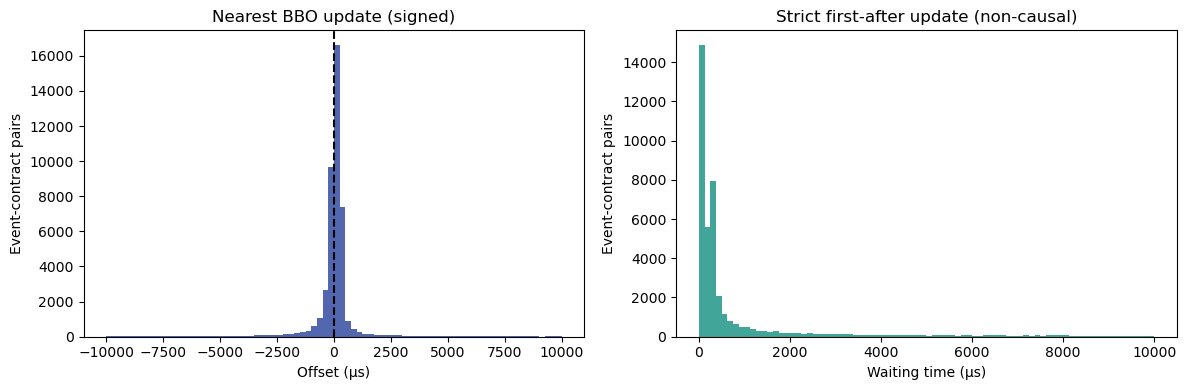

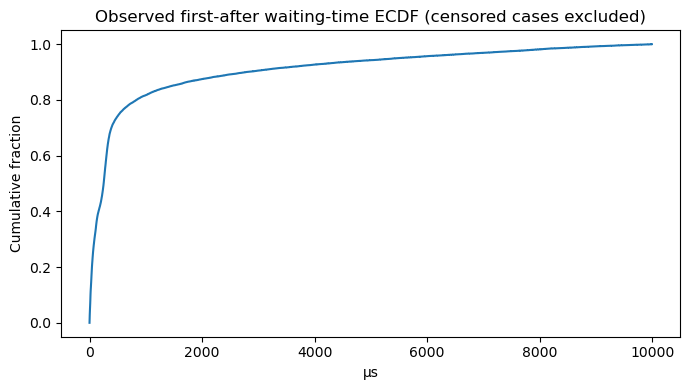

Observed forward updates before the next futures event:


,instrument_id,event_pairs,eligible_pre_state,nearest_matched,negative_nearest_fraction,simultaneous_fraction,nearest_median_us,nearest_p05_us,nearest_p95_us,forward_matched,first_after_median_us,first_after_p95_us,right_censored_fraction,contaminated_fraction
0,42646140,3830,3830,3830,0.236292,0.0,36.406,-300.4637,495.5491,3830,101.597,2850.8049,0.0,0.0
1,42662869,3651,3651,3651,0.224870,0.0,41.536,-317.5270,477.8500,3651,109.162,2791.6940,0.0,0.0
2,42866656,3681,3681,3681,0.242054,0.0,39.134,-305.7520,526.2520,3681,105.846,3068.1280,0.0,0.0
3,42874305,3772,3772,3772,0.218187,0.0,38.763,-253.5261,528.5628,3772,93.868,2224.6777,0.0,0.0
4,43046056,3443,3443,3443,0.218995,0.0,45.902,-296.2290,518.4268,3443,107.990,2961.4546,0.0,0.0
5,43078412,3664,3664,3664,0.223253,0.0,38.677,-282.7930,535.7605,3664,103.849,2395.5234,0.0,0.0


Symmetrically isolated futures events: 195


,instrument_id,event_pairs,eligible_pre_state,nearest_matched,negative_nearest_fraction,simultaneous_fraction,nearest_median_us,nearest_p05_us,nearest_p95_us,forward_matched,first_after_median_us,first_after_p95_us,right_censored_fraction,contaminated_fraction
0,42646140,195,195,178,0.129213,0.0,221.125,-361.3901,4719.5588,171,257.388,6584.4920,0.123077,0.0
1,42662869,195,195,174,0.132184,0.0,209.157,-447.8185,4691.9281,165,253.906,5569.6516,0.153846,0.0
2,42866656,195,195,168,0.166667,0.0,165.788,-420.7896,4990.2776,159,233.974,6219.8400,0.184615,0.0
3,42874305,195,195,179,0.162011,0.0,213.128,-1767.6726,3220.7200,166,263.852,4642.3290,0.148718,0.0
4,43046056,195,195,167,0.149701,0.0,224.742,-276.8358,1786.4406,152,278.282,4207.4389,0.220513,0.0
5,43078412,195,195,170,0.129412,0.0,212.030,-2080.2592,3616.3627,153,251.976,4692.3832,0.215385,0.0


Direction-consistent option midpoint updates around isolated events:


...

,instrument_id,pairs,event_offset_median_us,receive_offset_median_us,difference_median_us,difference_p95_us
0,42646140,6971,243.884,38451.229,37255.854,700452.97650
1,42662869,6783,251.860,36002.700,35102.876,576747.86130
2,42866656,6822,250.249,37135.116,35939.008,732045.02895
3,42874305,6969,240.966,36390.501,35543.589,693812.50660
4,43046056,6653,263.070,35102.557,34492.340,545378.09880
5,43078412,6849,255.030,37961.576,37190.542,731975.05740


Reception-delay differences (microseconds):


,instrument_id,recv_event_median_us,recv_event_p95_us,recv_event_p99_us,median_gap_to_futures_us
1,42874305,16690.477,334987.4570,861052.02810,16599.7295
2,42662869,16065.001,302550.3166,801781.56568,15974.2535
3,42866656,15352.817,337086.2687,881717.69054,15262.0695
4,42646140,16993.414,344484.9129,861086.25320,16902.6665
5,43046056,14983.857,308284.7326,776167.73104,14893.1095
6,43078412,20701.898,357685.1421,870461.72646,20611.1505


Reception-delay decomposition using ts_in_delta, when available:


,market,instrument_id,valid_delta_records,recv_minus_send_median_us,recv_minus_send_p95_us,send_minus_event_median_us,send_minus_event_p95_us
0,futures,10252,166088,12.670,14.8210,77.862,325.10725
1,options,42646140,50987,13.131,27358.5548,9591.763,318172.18540
2,options,42662869,41445,13.633,53074.0618,6813.881,263027.95600
3,options,42866656,43887,13.398,42918.2443,7017.342,303735.71640
4,options,42874305,49623,13.268,32436.1514,8927.684,307459.81560
5,options,43046056,34877,14.043,71694.4858,4784.893,253295.92300
6,options,43078412,43595,13.227,32876.7059,12081.270,327640.94190


In [10]:
SENSITIVITY=[]
for w in [100,1000,10000]:
    a=align_updates(F_EVENTS,O_CHANGES,window_us=w,max_age_us=MAX_PRE_QUOTE_AGE_US)
    x=a.nearest_us.dropna()
    SENSITIVITY.append(dict(window_us=w,pairs=len(a),matched=len(x),
        negative_fraction=float((x<0).mean()),near_zero_1us_fraction=float((x.abs()<=1).mean()),
        eligible_pre_fraction=float(a.eligible_pre_state.mean())))
SENSITIVITY=pd.DataFrame(SENSITIVITY)
display(SENSITIVITY)
RECEIVE_ALIGNED=align_updates(F_EVENTS,O_CHANGES,
    time_col='ts_recv',window_us=WINDOW_US,max_age_us=MAX_PRE_QUOTE_AGE_US)
RECEIVE_SUMMARY=offset_summary(RECEIVE_ALIGNED)
print('Reception-time matching: different matching rule/clock, not a clock-skew correction')
display(RECEIVE_SUMMARY)
control_events=F_EVENTS[F_EVENTS.ts_event+pd.Timedelta(milliseconds=20)<CORE_END].copy()
CONTROL_SUMMARY=pd.DataFrame(); CONTROL_BASE_SUMMARY=pd.DataFrame()
if not control_events.empty:
    CONTROL_BASE_SUMMARY=offset_summary(align_updates(control_events,O_CHANGES,window_us=WINDOW_US))
    control_events['ts_event']+=pd.Timedelta(milliseconds=20)
    # The next REAL futures event stays on its original timeline.
    real_times=ALL_F_EVENTS.ts_event.astype('int64').to_numpy()
    pos=np.searchsorted(real_times,control_events.ts_event.astype('int64').to_numpy(),side='right')
    control_events['next_event_time']=[pd.Timestamp(real_times[j],tz='UTC') if j<len(real_times) else pd.NaT for j in pos]
    CONTROL_SUMMARY=offset_summary(align_updates(control_events,O_CHANGES,window_us=WINDOW_US))
    print('Original comparable subset:'); display(CONTROL_BASE_SUMMARY)
    print('+20 ms placebo:'); display(CONTROL_SUMMARY)

fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].hist(ALIGNED.nearest_us.dropna(),bins=80,color='#5367b0')
axes[0].axvline(0,color='black',linestyle='--'); axes[0].set(title='Nearest BBO update (signed)',xlabel='Offset (μs)',ylabel='Event-contract pairs')
axes[1].hist(ALIGNED.first_after_us.dropna(),bins=80,color='#42a59a')
axes[1].set(title='Strict first-after update (non-causal)',xlabel='Waiting time (μs)',ylabel='Event-contract pairs')
fig.tight_layout(); fig.savefig(OUT/'lead_lag_diagnostics.png',dpi=180); plt.show()

# ECDF of observed waiting times; do not label it a survival estimator.
x=np.sort(ALIGNED.first_after_us.dropna())
fig,ax=plt.subplots(figsize=(7,4))
if len(x): ax.step(x,np.arange(1,len(x)+1)/len(x),where='post')
ax.set(title='Observed first-after waiting-time ECDF (censored cases excluded)',xlabel='μs',ylabel='Cumulative fraction')
fig.tight_layout(); fig.savefig(OUT/'waiting_time_ecdf.png',dpi=180); plt.show()


# Overlap-free, eligible observed updates: disclose the denominator lost to filtering.
CLEAN_ALIGNED=ALIGNED[ALIGNED.eligible_pre_state & ALIGNED.first_after_us.notna()
    & ALIGNED.another_futures_move_before_update.eq(0)].copy()
CLEAN_SUMMARY=offset_summary(CLEAN_ALIGNED)
print('Observed forward updates before the next futures event:'); display(CLEAN_SUMMARY)
ISOLATED=isolated_events(ALL_F_EVENTS,WINDOW_US)
ISOLATED_ALIGNED=align_updates(ISOLATED,O_CHANGES,window_us=WINDOW_US,max_age_us=MAX_PRE_QUOTE_AGE_US)
ISOLATED_SUMMARY=offset_summary(ISOLATED_ALIGNED)
print('Symmetrically isolated futures events:',len(ISOLATED)); display(ISOLATED_SUMMARY)
DIRECTIONAL=directional_diagnostics(ISOLATED,O_CHANGES,SELECTED_OPTIONS,WINDOW_US)
DIRECTIONAL_SUMMARY=offset_summary(DIRECTIONAL)
print('Direction-consistent option midpoint updates around isolated events:'); display(DIRECTIONAL_SUMMARY)

# Pair the SAME event/update on both clocks. Rematching by reception time alone
# cannot measure how the offset of a fixed pair changes between clocks.
clock_pairs=[]
for iid,g in O_CHANGES.groupby('instrument_id'):
    g=g.sort_values(['ts_event','_arrival'],kind='stable').drop_duplicates('ts_event',keep='last')
    t=g.ts_event.astype('int64').to_numpy(); r=g.ts_recv.astype('int64').to_numpy()
    e=F_EVENTS.ts_event.astype('int64').to_numpy(); er=F_EVENTS.ts_recv.astype('int64').to_numpy()
    pos=np.searchsorted(t,e,side='right'); ok=pos<len(t)
    j=np.clip(pos,0,len(t)-1); delta=t[j]-e
    ok &= delta<=WINDOW_US*1000
    clock_pairs.append(pd.DataFrame({'instrument_id':int(iid),
        'event_offset_us':delta[ok]/1000,'receive_offset_us':(r[j][ok]-er[ok])/1000,
        'clock_offset_difference_us':((r[j][ok]-er[ok])-delta[ok])/1000}))
PAIRED_CLOCKS=pd.concat(clock_pairs,ignore_index=True) if clock_pairs else pd.DataFrame()
clock_rows=[]
for iid,g in PAIRED_CLOCKS.groupby('instrument_id'):
    clock_rows.append(dict(instrument_id=int(iid),pairs=len(g),
        event_offset_median_us=g.event_offset_us.median(),
        receive_offset_median_us=g.receive_offset_us.median(),
        difference_median_us=g.clock_offset_difference_us.median(),
        difference_p95_us=g.clock_offset_difference_us.quantile(.95)))
PAIRED_CLOCK_SUMMARY=pd.DataFrame(clock_rows)
print('Same-pair event/reception-clock comparison:'); display(PAIRED_CLOCK_SUMMARY)

f_delay=float(QUALITY.loc[QUALITY.market=='futures','recv_event_median_us'].median())
opt_quality=QUALITY[QUALITY.market=='options'].copy()
opt_quality['median_gap_to_futures_us']=opt_quality.recv_event_median_us-f_delay
RECEPTION_COMPARISON=opt_quality[['instrument_id','recv_event_median_us','recv_event_p95_us',
    'recv_event_p99_us','median_gap_to_futures_us']]
print('Reception-delay differences (microseconds):'); display(RECEPTION_COMPARISON)


# If the sending timestamp delta is present, decompose reception delay.
# This distinguishes two observed intervals without assigning a physical cause
# or assuming that clocks share a proven synchronization error bound.
component_rows=[]
for market,raw in [('futures',FUTURES_RAW),('options',OPTIONS_RAW)]:
    if 'ts_in_delta' not in raw:continue
    for iid,g in raw.groupby('instrument_id'):
        delta=g.ts_in_delta
        if pd.api.types.is_timedelta64_dtype(delta):
            receive_minus_send=delta.dt.total_seconds()*1e6
        else:
            receive_minus_send=pd.to_numeric(delta,errors='coerce')/1000
        receive_minus_send=receive_minus_send.where(receive_minus_send.abs()<2_147_483.647)
        total=(g.ts_recv-g.ts_event).dt.total_seconds()*1e6
        send_minus_event=total-receive_minus_send
        component_rows.append(dict(market=market,instrument_id=int(iid),valid_delta_records=int(receive_minus_send.notna().sum()),
            recv_minus_send_median_us=receive_minus_send.median(),recv_minus_send_p95_us=receive_minus_send.quantile(.95),
            send_minus_event_median_us=send_minus_event.median(),send_minus_event_p95_us=send_minus_event.quantile(.95)))
RECEPTION_COMPONENTS=pd.DataFrame(component_rows)
print('Reception-delay decomposition using ts_in_delta, when available:'); display(RECEPTION_COMPONENTS)


## 9. Report and assessment

Generate a report from the corrected results, including numerical findings, review flags, task coverage, and recommendations. The notebook displays the report as well as saving it, so a reviewer can see the interpretation in the executed notebook.


In [11]:
usable=bool(AVAILABILITY.positive_overlap.any() and ALIGNED.eligible_pre_state.any()
    and ALIGNED.nearest_us.notna().any())
matched_forward=ALIGNED[ALIGNED.first_after_us.notna()]
overlap_rate=float(matched_forward.another_futures_move_before_update.mean()) if len(matched_forward) else np.nan
reception_gap=float(RECEPTION_COMPARISON.median_gap_to_futures_us.abs().max())
negative_fraction=float((ALIGNED.nearest_us.dropna()<0).mean())
isolated_matched=int(ISOLATED_ALIGNED.nearest_us.notna().sum()) if not ISOLATED_ALIGNED.empty else 0
warnings=[]
if reception_gap>MAX_MEDIAN_RECEPTION_GAP_US:
    warnings.append(f'Largest absolute option/futures median reception-delay gap is {reception_gap:,.1f} us, above the {MAX_MEDIAN_RECEPTION_GAP_US:,.0f} us review threshold.')
if pd.notna(overlap_rate) and overlap_rate>MAX_OVERLAP_FRACTION:
    warnings.append(f'{overlap_rate:.1%} of observed first-after matches follow another futures move. All-pair waiting times cannot be interpreted as single-event reactions.')
if isolated_matched<MIN_ISOLATED_PAIRS:
    warnings.append(f'Only {isolated_matched} isolated event-contract pairs have a nearest match; this is below the {MIN_ISOLATED_PAIRS} descriptive-sample threshold.')
if QUALITY[['missing_event','missing_recv','event_backsteps','recv_backsteps','negative_recv_event']].to_numpy().sum()>0:
    warnings.append('Raw timestamp anomalies need review; see timestamp_quality.csv.')
DECISION='Conditional Go — data available; microsecond comparability unverified' if usable else 'No-Go for selected sample'
MICROSECOND_STATUS='Not validated: no independent cross-engine clock error bound'
if warnings: MICROSECOND_STATUS += '; empirical concerns require follow-up'
TASK_STATUS=pd.DataFrame([
    ['Futures MBP-1 availability','Verified for sample',f'{FUTURE_SYMBOL}: {len(FUTURES_RAW):,} records'],
    ['0DTE option MBP-1 availability','Verified for sample',f'{len(SELECTED_OPTIONS)} selected contracts; {len(OPTIONS_RAW):,} records'],
    ['Historical course-license range','Metadata recorded; full license coverage unverified','Current-key range does not establish free access to every contract/date'],
    ['Common sample retrieval and alignment','Verified for sample',f'{SAMPLE_DATE}; {len(F_EVENTS):,} corrected midpoint events'],
    ['Timestamp fields and quality','Checked','Definitions and per-contract quality/delay tables'],
    ['Zero/near-zero lead-lag artifacts','Descriptive checks complete','Signed offsets, window sensitivity, placebo, isolated-event checks'],
    ['Systematically negative causal reaction latency','Not identified from MBP-1 alone','Direction-consistent signed-update proxy reported; causality and clock skew remain unresolved'],
    ['Timestamp comparability and limitations','Conditional assessment documented',MICROSECOND_STATUS]
],columns=['task','status','evidence_or_limitation'])
TABLES={'timestamp_quality':QUALITY,'instrument_availability':AVAILABILITY,
    'lead_lag_summary':SUMMARY,'window_sensitivity':SENSITIVITY,'receive_clock_summary':RECEIVE_SUMMARY,
    'placebo_summary':CONTROL_SUMMARY,'placebo_baseline_summary':CONTROL_BASE_SUMMARY,
    'event_correction':EVENT_CORRECTION,'uncontaminated_forward_summary':CLEAN_SUMMARY,
    'isolated_event_summary':ISOLATED_SUMMARY,'direction_consistent_summary':DIRECTIONAL_SUMMARY,
    'same_pair_clock_summary':PAIRED_CLOCK_SUMMARY,'reception_delay_comparison':RECEPTION_COMPARISON,
    'task_status':TASK_STATUS,'reception_delay_components':RECEPTION_COMPONENTS}
for name,df in TABLES.items(): df.to_csv(OUT/f'{name}.csv',index=False)
versions={name:importlib.metadata.version(name) for name in ['databento','pandas','numpy','matplotlib']}
(OUT/'requirements-validated.txt').write_text('\n'.join(f'{k}=={v}' for k,v in versions.items())+'\n',encoding='utf-8')
manifest=dict(dataset=DATASET,schema='mbp-1',sample_date=SAMPLE_DATE,
    core_start=str(CORE_START),core_end=str(CORE_END),future_symbol=FUTURE_SYMBOL,option_symbols=OPTION_SYMBOLS,
    futures_records=len(FUTURES_RAW),options_records=len(OPTIONS_RAW),corrected_events=len(F_EVENTS),
    legacy_events=len(LEGACY_EVENTS),synthetic_tests_passed=SYNTHETIC_TESTS_PASSED,
    decision=DECISION,microsecond_status=MICROSECOND_STATUS,warnings=warnings,
    observed_forward_overlap_fraction=overlap_rate,isolated_events=len(ISOLATED),isolated_matched_pairs=isolated_matched,
    available_range=DATA_RANGE,requests=REQUEST_LOG,versions=versions,python=platform.python_version(),
    independently_verified_clock_error_bound_ns=None)
(OUT/'validation_manifest.json').write_text(json.dumps(manifest,indent=2,default=str),encoding='utf-8')
def table_text(df):
    return '```text\n'+(df.to_string(index=False) if len(df) else 'No observations in this sample')+'\n```'
report=f"""# Issue 1: Data availability and timestamp assessment

## Sample and access
Dataset: {DATASET}; schema: mbp-1. Sample: {SAMPLE_DATE}, {CORE_START} to {CORE_END}.
Future: {FUTURE_SYMBOL}; options: {', '.join(OPTION_SYMBOLS)}.
Retrieved rows: {len(FUTURES_RAW):,} futures and {len(OPTIONS_RAW):,} options.
Run this notebook with the API key in DATABENTO_API_KEY or the hidden prompt. Dependencies and request metadata are saved alongside this report. Local cache entries reuse identical requests.

### Current-key historical metadata
```json
{json.dumps(DATA_RANGE,indent=2,default=str)}
```
This is the range returned for the current key. Successful requests verify access only for this sample. Full course-license coverage and free access across the entire range have not been independently established.

### Contracts and common coverage
The future is selected by nearest unexpired calendar maturity. Options are linked through instrument definitions, including daily/weekly roots; expiration must fall on the sample's Chicago date and after the sample window.
{table_text(AVAILABILITY)}

## Timestamp definitions and quality
For CME MDP 3.0, ts_event is the matching-engine-received timestamp (60-TransactTime). ts_recv is Databento capture-server reception time. Their difference measures reception delay, not market-maker reaction latency. Timestamp precision does not establish clock accuracy.
{table_text(QUALITY)}
Reception delays are materially different when the option/futures median gap exceeds the review threshold. This can reflect processing, dissemination, batching or capture-path effects; these summaries do not identify the cause or prove clock skew. It also means reception-time matching answers a different question from exchange-event-time matching.
{table_text(RECEPTION_COMPARISON)}

### Sending-timestamp decomposition
Where ts_in_delta is available, recv-minus-send is ts_in_delta / 1,000 in microseconds; send-minus-event is total reception delay minus that interval. This helps locate the observed gap, but does not establish clock accuracy or identify an exchange/feed-path cause. Missing or sentinel deltas are excluded.
{table_text(RECEPTION_COMPONENTS)}

## Corrected event construction
Final quote states are aggregated at each instrument/event timestamp BEFORE changes are computed. Invalid final quotes break the comparison. This prevents a later size-only update at the same timestamp from erasing a price move.
{table_text(EVENT_CORRECTION)}
Regression tests passed: {SYNTHETIC_TESTS_PASSED}. Old notebook counts should not be used in place of these corrected results.

## Signed updates and waiting times
Nearest matching searches both directions within +/-{WINDOW_US} us. Across matched pairs, {negative_fraction:.1%} of nearest updates occur before the futures event. These are signed update offsets, not identified negative causal reactions. First-after matching is strictly later by definition. Its quantiles exclude unmatched/censored cases and describe observed waits within the configured horizon.
{table_text(SUMMARY)}

### Window sensitivity
{table_text(SENSITIVITY)}

### Overlapping events
Among observed forward matches, {overlap_rate:.1%} follow another futures midpoint move. Censored pairs have unknown overlap status rather than a fabricated zero. The following table restricts to eligible observed updates before the next futures event; this filtering changes the population and does not eliminate unrelated option activity.
{table_text(CLEAN_SUMMARY)}

### Isolated events and signed directional proxy
An isolated event has no other midpoint event in the +/-{WINDOW_US} us window. There are {len(ISOLATED):,} isolated events and {isolated_matched:,} nearest matched event-contract pairs. Endpoints with unknown neighboring events are excluded.
{table_text(ISOLATED_SUMMARY)}
The directional proxy selects call midpoint changes in the futures-move direction and put changes in the opposite direction. It retains both negative and positive offsets. Direction consistency is not a causal identification rule; independent information and shared news remain possible explanations.
{table_text(DIRECTIONAL_SUMMARY)}

### Reception clock and same-pair comparison
The reception-time matcher now measures overlap against the next reception-time futures event. This is separate from the same-pair comparison below: the latter holds the futures/option pair fixed and shows how its offset changes between the two clocks.
{table_text(RECEIVE_SUMMARY)}
{table_text(PAIRED_CLOCK_SUMMARY)}

### Placebo
The +20 ms placebo shifts the event anchor but keeps real futures events on their actual timeline when assessing overlap. It is a descriptive control for update intensity, not a clock calibration.
{table_text(CONTROL_BASE_SUMMARY)}
{table_text(CONTROL_SUMMARY)}

## Assessment
**{DECISION}**
**Microsecond measurement status:** {MICROSECOND_STATUS}.
The sample supports data ingestion and further method development. It does not yet support causal microsecond reaction-latency claims. The assessment is not changed to Go simply because data downloads succeeded.

### Findings requiring review
{chr(10).join('- '+w for w in warnings) if warnings else '- No configured empirical review threshold was exceeded. Independent clock comparability remains unverified.'}

## Task coverage
{table_text(TASK_STATUS)}

## Next steps and scope
1. Investigate the option/futures reception-delay gap using ts_in_delta and channel/feed-path information where available. Do not treat reception delay as a clock-skew estimate.
2. Repeat across additional windows/dates if isolated-event matches are sparse. Do not expand to a profitability study under this issue.
3. Obtain provider or exchange evidence for cross-engine synchronization accuracy. Without an error bound, keep microsecond timing claims conditional.
4. Report descriptive results in 100 us, 1 ms and 10 ms windows, with denominators, censoring and overlap exclusions. Coarser buckets do not cure unknown clock bias.
5. Later issues must define economic reaction/stale-window resolution. Do not clamp negative offsets or silently shift timestamps to fit an expected result.

## References
- https://databento.com/docs/venues-and-datasets/glbx-mdp3
- https://databento.com/docs/examples/futures/futures-product-options
- https://databento.com/docs/api-reference-historical

## Reproducibility and publication
Only aggregate tables, figures and metadata are exported here. Keep raw DBN files and credentials out of Git. Run this revision before citing its findings; outputs from the previous version are not reused.
"""
(OUT/'data_feasibility.md').write_text(report,encoding='utf-8')
print('Decision:',DECISION)
print('Microsecond status:',MICROSECOND_STATUS)
for warning in warnings: print('Review:',warning)
display(TASK_STATUS)
display(Markdown(report))
print('Reports saved to:',OUT)


Decision: Conditional Go — data available; microsecond comparability unverified
Microsecond status: Not validated: no independent cross-engine clock error bound; empirical concerns require follow-up
Review: Largest absolute option/futures median reception-delay gap is 20,611.2 us, above the 1,000 us review threshold.
Review: 46.3% of observed first-after matches follow another futures move. All-pair waiting times cannot be interpreted as single-event reactions.


,task,status,evidence_or_limitation
0,Futures MBP-1 availability,Verified for sample,"ESZ6: 166,088 records"
1,0DTE option MBP-1 availability,Verified for sample,"6 selected contracts; 264,414 records"
2,Historical course-license range,Metadata recorded; full license coverage unver...,Current-key range does not establish free acce...
3,Common sample retrieval and alignment,Verified for sample,"2026-10-08; 7,519 corrected midpoint events"
4,Timestamp fields and quality,Checked,Definitions and per-contract quality/delay tables
5,Zero/near-zero lead-lag artifacts,Descriptive checks complete,"Signed offsets, window sensitivity, placebo, i..."
6,Systematically negative causal reaction latency,Not identified from MBP-1 alone,Direction-consistent signed-update proxy repor...
7,Timestamp comparability and limitations,Conditional assessment documented,Not validated: no independent cross-engine clo...


# Issue 1: Data availability and timestamp assessment

## Sample and access
Dataset: GLBX.MDP3; schema: mbp-1. Sample: 2026-10-08, 2026-10-08 14:00:00+00:00 to 2026-10-08 14:10:00+00:00.
Future: ESZ6; options: E2DV6 P7830, E2DV6 C7830, E2DV6 P7835, E2DV6 C7835, E2DV6 C7825, E2DV6 P7825.
Retrieved rows: 166,088 futures and 264,414 options.
Run this notebook with the API key in DATABENTO_API_KEY or the hidden prompt. Dependencies and request metadata are saved alongside this report. Local cache entries reuse identical requests.

### Current-key historical metadata
```json
{
  "start": "2010-06-06T00:00:00.000000000Z",
  "end": "2026-10-11T13:08:20.817591000Z",
  "schema": {
    "mbo": {
      "start": "2017-05-21T00:00:00.000000000Z",
      "end": "2026-10-11T13:08:20.817591000Z"
    },
    "mbp-1": {
      "start": "2010-06-06T00:00:00.000000000Z",
      "end": "2026-10-11T13:08:20.817591000Z"
    },
    "mbp-10": {
      "start": "2010-06-06T00:00:00.000000000Z",
      "end": "2026-10-11T13:08:20.817591000Z"
    },
    "tbbo": {
      "start": "2010-06-06T00:00:00.000000000Z",
      "end": "2026-10-11T13:08:20.817591000Z"
    },
    "trades": {
      "start": "2010-06-06T00:00:00.000000000Z",
      "end": "2026-10-11T13:08:20.817591000Z"
    },
    "bbo-1s": {
      "start": "2010-06-06T00:00:00.000000000Z",
      "end": "2026-10-11T13:08:20.817591000Z"
    },
    "bbo-1m": {
      "start": "2010-06-06T00:00:00.000000000Z",
      "end": "2026-10-11T13:08:20.817591000Z"
    },
    "ohlcv-1s": {
      "start": "2010-06-06T00:00:00.000000000Z",
      "end": "2026-10-11T13:08:20.817591000Z"
    },
    "ohlcv-1m": {
      "start": "2010-06-06T00:00:00.000000000Z",
      "end": "2026-10-11T13:08:20.817591000Z"
    },
    "ohlcv-1h": {
      "start": "2010-06-06T00:00:00.000000000Z",
      "end": "2026-10-11T13:08:20.817591000Z"
    },
    "ohlcv-1d": {
      "start": "2010-06-06T00:00:00.000000000Z",
      "end": "2026-10-11T00:00:00.000000000Z"
    },
    "definition": {
      "start": "2010-06-06T00:00:00.000000000Z",
      "end": "2026-10-11T13:08:20.817591000Z"
    },
    "statistics": {
      "start": "2010-06-06T00:00:00.000000000Z",
      "end": "2026-10-11T13:08:20.817591000Z"
    },
    "status": {
      "start": "2010-06-06T00:00:00.000000000Z",
      "end": "2026-10-11T13:08:20.817591000Z"
    },
    "cmbp-1": {
      "start": "2017-05-21T00:00:00.000000000Z",
      "end": "2026-10-11T13:08:20.817591000Z"
    },
    "cbbo-1s": {
      "start": "2017-05-21T00:00:00.000000000Z",
      "end": "2026-10-11T13:08:20.817591000Z"
    },
    "cbbo-1m": {
      "start": "2017-05-21T00:00:00.000000000Z",
      "end": "2026-10-11T13:08:20.817591000Z"
    }
  }
}
```
This is the range returned for the current key. Successful requests verify access only for this sample. Full course-license coverage and free access across the entire range have not been independently established.

### Contracts and common coverage
The future is selected by nearest unexpired calendar maturity. Options are linked through instrument definitions, including daily/weekly roots; expiration must fall on the sample's Chicago date and after the sample window.
```text
     symbol  instrument_id  records              common_start                common_end  positive_overlap
E2DV6 P7830       42646140    50987 2026-10-08 14:00:00+00:00 2026-10-08 14:10:00+00:00              True
E2DV6 C7830       42662869    41445 2026-10-08 14:00:00+00:00 2026-10-08 14:10:00+00:00              True
E2DV6 P7835       42866656    43887 2026-10-08 14:00:00+00:00 2026-10-08 14:10:00+00:00              True
E2DV6 C7835       42874305    49623 2026-10-08 14:00:00+00:00 2026-10-08 14:10:00+00:00              True
E2DV6 C7825       43046056    34877 2026-10-08 14:00:00+00:00 2026-10-08 14:10:00+00:00              True
E2DV6 P7825       43078412    43595 2026-10-08 14:00:00+00:00 2026-10-08 14:10:00+00:00              True
```

## Timestamp definitions and quality
For CME MDP 3.0, ts_event is the matching-engine-received timestamp (60-TransactTime). ts_recv is Databento capture-server reception time. Their difference measures reception delay, not market-maker reaction latency. Timestamp precision does not establish clock accuracy.
```text
 market  instrument_id  records  missing_event  missing_recv  event_backsteps  recv_backsteps  duplicate_event_times  bad_recv_or_snapshot  negative_recv_event  recv_event_median_us  recv_event_p95_us  recv_event_p99_us
futures          10252   166088              0             0                0               0                   8399                     0                    0               90.7475           338.3020          642.77818
options       42874305    49623              0             0                0               0                     40                     0                    0            16690.4770        334987.4570       861052.02810
options       42662869    41445              0             0                0               0                     29                     0                    0            16065.0010        302550.3166       801781.56568
options       42866656    43887              0             0                0               0                     35                     0                    0            15352.8170        337086.2687       881717.69054
options       42646140    50987              0             0                0               0                     53                     0                    0            16993.4140        344484.9129       861086.25320
options       43046056    34877              0             0                0               0                     39                     0                    0            14983.8570        308284.7326       776167.73104
options       43078412    43595              0             0                0               0                     39                     0                    0            20701.8980        357685.1421       870461.72646
```
Reception delays are materially different when the option/futures median gap exceeds the review threshold. This can reflect processing, dissemination, batching or capture-path effects; these summaries do not identify the cause or prove clock skew. It also means reception-time matching answers a different question from exchange-event-time matching.
```text
 instrument_id  recv_event_median_us  recv_event_p95_us  recv_event_p99_us  median_gap_to_futures_us
      42874305             16690.477        334987.4570       861052.02810                16599.7295
      42662869             16065.001        302550.3166       801781.56568                15974.2535
      42866656             15352.817        337086.2687       881717.69054                15262.0695
      42646140             16993.414        344484.9129       861086.25320                16902.6665
      43046056             14983.857        308284.7326       776167.73104                14893.1095
      43078412             20701.898        357685.1421       870461.72646                20611.1505
```

### Sending-timestamp decomposition
Where ts_in_delta is available, recv-minus-send is ts_in_delta / 1,000 in microseconds; send-minus-event is total reception delay minus that interval. This helps locate the observed gap, but does not establish clock accuracy or identify an exchange/feed-path cause. Missing or sentinel deltas are excluded.
```text
 market  instrument_id  valid_delta_records  recv_minus_send_median_us  recv_minus_send_p95_us  send_minus_event_median_us  send_minus_event_p95_us
futures          10252               166088                     12.670                 14.8210                      77.862                325.10725
options       42646140                50987                     13.131              27358.5548                    9591.763             318172.18540
options       42662869                41445                     13.633              53074.0618                    6813.881             263027.95600
options       42866656                43887                     13.398              42918.2443                    7017.342             303735.71640
options       42874305                49623                     13.268              32436.1514                    8927.684             307459.81560
options       43046056                34877                     14.043              71694.4858                    4784.893             253295.92300
options       43078412                43595                     13.227              32876.7059                   12081.270             327640.94190
```

## Corrected event construction
Final quote states are aggregated at each instrument/event timestamp BEFORE changes are computed. Invalid final quotes break the comparison. This prevents a later size-only update at the same timestamp from erasing a price move.
```text
 legacy_events  corrected_events  event_count_difference
          7519              7519                       0
```
Regression tests passed: 17. Old notebook counts should not be used in place of these corrected results.

## Signed updates and waiting times
Nearest matching searches both directions within +/-10000 us. Across matched pairs, 37.2% of nearest updates occur before the futures event. These are signed update offsets, not identified negative causal reactions. First-after matching is strictly later by definition. Its quantiles exclude unmatched/censored cases and describe observed waits within the configured horizon.
```text
 instrument_id  event_pairs  eligible_pre_state  nearest_matched  negative_nearest_fraction  simultaneous_fraction  nearest_median_us  nearest_p05_us  nearest_p95_us  forward_matched  first_after_median_us  first_after_p95_us  right_censored_fraction  contaminated_fraction
      42646140         7519                7519             7353                   0.371277                    0.0             26.048      -1118.1092        760.4612             6971                243.884           5599.2250                 0.072882               0.450581
      42662869         7519                7519             7297                   0.376730                    0.0             31.624      -1247.2028        704.7364             6783                251.860           5360.7022                 0.097885               0.461743
      42866656         7519                7519             7309                   0.385005                    0.0             28.796      -1282.5060        984.4676             6822                250.249           5378.6980                 0.092698               0.460422
      42874305         7519                7519             7371                   0.361959                    0.0             31.346      -1196.5030        794.3250             6969                240.966           5100.7096                 0.073148               0.458746
      43046056         7519                7519             7205                   0.372241                    0.0             37.170      -1620.3492        980.4472             6653                263.070           5721.8716                 0.115175               0.482489
      43078412         7519                7519             7267                   0.367552                    0.0             28.596      -1083.6954        941.5794             6849                255.030           5783.7148                 0.089108               0.465031
```

### Window sensitivity
```text
 window_us  pairs  matched  negative_fraction  near_zero_1us_fraction  eligible_pre_fraction
       100  45114    17392           0.349126                0.030416                    1.0
      1000  45114    39306           0.350583                0.013459                    1.0
     10000  45114    43802           0.372449                0.012077                    1.0
```

### Overlapping events
Among observed forward matches, 46.3% follow another futures midpoint move. Censored pairs have unknown overlap status rather than a fabricated zero. The following table restricts to eligible observed updates before the next futures event; this filtering changes the population and does not eliminate unrelated option activity.
```text
 instrument_id  event_pairs  eligible_pre_state  nearest_matched  negative_nearest_fraction  simultaneous_fraction  nearest_median_us  nearest_p05_us  nearest_p95_us  forward_matched  first_after_median_us  first_after_p95_us  right_censored_fraction  contaminated_fraction
      42646140         3830                3830             3830                   0.236292                    0.0             36.406       -300.4637        495.5491             3830                101.597           2850.8049                      0.0                    0.0
      42662869         3651                3651             3651                   0.224870                    0.0             41.536       -317.5270        477.8500             3651                109.162           2791.6940                      0.0                    0.0
      42866656         3681                3681             3681                   0.242054                    0.0             39.134       -305.7520        526.2520             3681                105.846           3068.1280                      0.0                    0.0
      42874305         3772                3772             3772                   0.218187                    0.0             38.763       -253.5261        528.5628             3772                 93.868           2224.6777                      0.0                    0.0
      43046056         3443                3443             3443                   0.218995                    0.0             45.902       -296.2290        518.4268             3443                107.990           2961.4546                      0.0                    0.0
      43078412         3664                3664             3664                   0.223253                    0.0             38.677       -282.7930        535.7605             3664                103.849           2395.5234                      0.0                    0.0
```

### Isolated events and signed directional proxy
An isolated event has no other midpoint event in the +/-10000 us window. There are 195 isolated events and 1,036 nearest matched event-contract pairs. Endpoints with unknown neighboring events are excluded.
```text
 instrument_id  event_pairs  eligible_pre_state  nearest_matched  negative_nearest_fraction  simultaneous_fraction  nearest_median_us  nearest_p05_us  nearest_p95_us  forward_matched  first_after_median_us  first_after_p95_us  right_censored_fraction  contaminated_fraction
      42646140          195                 195              178                   0.129213                    0.0            221.125       -361.3901       4719.5588              171                257.388           6584.4920                 0.123077                    0.0
      42662869          195                 195              174                   0.132184                    0.0            209.157       -447.8185       4691.9281              165                253.906           5569.6516                 0.153846                    0.0
      42866656          195                 195              168                   0.166667                    0.0            165.788       -420.7896       4990.2776              159                233.974           6219.8400                 0.184615                    0.0
      42874305          195                 195              179                   0.162011                    0.0            213.128      -1767.6726       3220.7200              166                263.852           4642.3290                 0.148718                    0.0
      43046056          195                 195              167                   0.149701                    0.0            224.742       -276.8358       1786.4406              152                278.282           4207.4389                 0.220513                    0.0
      43078412          195                 195              170                   0.129412                    0.0            212.030      -2080.2592       3616.3627              153                251.976           4692.3832                 0.215385                    0.0
```
The directional proxy selects call midpoint changes in the futures-move direction and put changes in the opposite direction. It retains both negative and positive offsets. Direction consistency is not a causal identification rule; independent information and shared news remain possible explanations.
```text
 instrument_id  event_pairs  eligible_pre_state  nearest_matched  negative_nearest_fraction  simultaneous_fraction  nearest_median_us  nearest_p05_us  nearest_p95_us  forward_matched  first_after_median_us  first_after_p95_us  right_censored_fraction  contaminated_fraction
      42646140          195                 193               55                   0.181818                    0.0            279.290      -4444.8706       5335.6248               45                354.146           5699.5328                 0.769231                    0.0
      42662869          195                 195               73                   0.191781                    0.0            263.420      -3631.4752       2918.2708               60                336.036           5599.2986                 0.692308                    0.0
      42866656          195                 194               79                   0.177215                    0.0            258.920      -1826.7372       4790.7024               66                362.671           5026.5640                 0.661538                    0.0
      42874305          195                 195               62                   0.225806                    0.0            257.024      -2615.3699       1818.2188               51                341.518           5673.9890                 0.738462                    0.0
      43046056          195                 194               81                   0.148148                    0.0            341.358      -1915.6180       4068.1720               72                424.601           6357.9498                 0.630769                    0.0
      43078412          195                 191               57                   0.192982                    0.0            334.156      -4725.2616       6688.0392               47                375.278           7664.6022                 0.758974                    0.0
```

### Reception clock and same-pair comparison
The reception-time matcher now measures overlap against the next reception-time futures event. This is separate from the same-pair comparison below: the latter holds the futures/option pair fixed and shows how its offset changes between the two clocks.
```text
 instrument_id  event_pairs  eligible_pre_state  nearest_matched  negative_nearest_fraction  simultaneous_fraction  nearest_median_us  nearest_p05_us  nearest_p95_us  forward_matched  first_after_median_us  first_after_p95_us  right_censored_fraction  contaminated_fraction
      42646140         7519                7519             6658                   0.403875                    0.0           316.3220     -5095.69885      6252.60510             5726               2014.340          8398.68275                 0.238463               0.649494
      42662869         7519                7519             6483                   0.399661                    0.0           383.3280     -5798.60960      6624.74670             5516               2064.681          8455.50500                 0.266392               0.650653
      42866656         7519                7519             6527                   0.438946                    0.0           225.6070     -6317.58130      6114.65200             5463               2141.168          8531.69020                 0.273441               0.649643
      42874305         7519                7519             6703                   0.419961                    0.0           268.4010     -6023.61140      6742.39280             5721               1967.821          8541.50300                 0.239128               0.652159
      43046056         7519                7519             6288                   0.385655                    0.0           456.5900     -5888.64200      6704.23385             5271               2067.471          8470.77300                 0.298976               0.658509
      43078412         7519                7519             6458                   0.428925                    0.0           275.7165     -5868.99530      6656.87710             5458               2267.806          8277.56930                 0.274106               0.645291
```
```text
 instrument_id  pairs  event_offset_median_us  receive_offset_median_us  difference_median_us  difference_p95_us
      42646140   6971                 243.884                 38451.229             37255.854       700452.97650
      42662869   6783                 251.860                 36002.700             35102.876       576747.86130
      42866656   6822                 250.249                 37135.116             35939.008       732045.02895
      42874305   6969                 240.966                 36390.501             35543.589       693812.50660
      43046056   6653                 263.070                 35102.557             34492.340       545378.09880
      43078412   6849                 255.030                 37961.576             37190.542       731975.05740
```

### Placebo
The +20 ms placebo shifts the event anchor but keeps real futures events on their actual timeline when assessing overlap. It is a descriptive control for update intensity, not a clock calibration.
```text
 instrument_id  event_pairs  eligible_pre_state  nearest_matched  negative_nearest_fraction  simultaneous_fraction  nearest_median_us  nearest_p05_us  nearest_p95_us  forward_matched  first_after_median_us  first_after_p95_us  right_censored_fraction  contaminated_fraction
      42646140         7519                7519             7353                   0.371277                    0.0             26.048      -1118.1092        760.4612             6971                243.884           5599.2250                 0.072882               0.450581
      42662869         7519                7519             7297                   0.376730                    0.0             31.624      -1247.2028        704.7364             6783                251.860           5360.7022                 0.097885               0.461743
      42866656         7519                7519             7309                   0.385005                    0.0             28.796      -1282.5060        984.4676             6822                250.249           5378.6980                 0.092698               0.460422
      42874305         7519                7519             7371                   0.361959                    0.0             31.346      -1196.5030        794.3250             6969                240.966           5100.7096                 0.073148               0.458746
      43046056         7519                7519             7205                   0.372241                    0.0             37.170      -1620.3492        980.4472             6653                263.070           5721.8716                 0.115175               0.482489
      43078412         7519                7519             7267                   0.367552                    0.0             28.596      -1083.6954        941.5794             6849                255.030           5783.7148                 0.089108               0.465031
```
```text
 instrument_id  event_pairs  eligible_pre_state  nearest_matched  negative_nearest_fraction  simultaneous_fraction  nearest_median_us  nearest_p05_us  nearest_p95_us  forward_matched  first_after_median_us  first_after_p95_us  right_censored_fraction  contaminated_fraction
      42646140         7519                7519             6344                   0.495113                    0.0             28.316      -7869.2747       7445.8632             4829               3892.256           8833.8600                 0.357760               0.121971
      42662869         7519                7519             5936                   0.527460                    0.0           -232.123      -8182.9225       7797.6135             4216               3754.527           9099.9850                 0.439287               0.138046
      42866656         7519                7519             6006                   0.532634                    0.0           -296.758      -8442.4930       7541.6080             4172               3770.751           9033.4768                 0.445139               0.144295
      42874305         7519                7519             6286                   0.497773                    0.0             21.240      -8027.5575       7937.6235             4695               4137.374           9096.9234                 0.375582               0.142918
      43046056         7519                7519             5432                   0.552835                    0.0           -451.299      -8606.9923       7505.8851             3485               3615.686           9107.8880                 0.536508               0.165280
      43078412         7519                7519             6088                   0.502300                    0.0            -14.947      -8253.6758       7834.0385             4545               4009.102           8943.2676                 0.395531               0.112871
```

## Assessment
**Conditional Go — data available; microsecond comparability unverified**
**Microsecond measurement status:** Not validated: no independent cross-engine clock error bound; empirical concerns require follow-up.
The sample supports data ingestion and further method development. It does not yet support causal microsecond reaction-latency claims. The assessment is not changed to Go simply because data downloads succeeded.

### Findings requiring review
- Largest absolute option/futures median reception-delay gap is 20,611.2 us, above the 1,000 us review threshold.
- 46.3% of observed first-after matches follow another futures move. All-pair waiting times cannot be interpreted as single-event reactions.

## Task coverage
```text
                                           task                                              status                                                                             evidence_or_limitation
                     Futures MBP-1 availability                                 Verified for sample                                                                              ESZ6: 166,088 records
                 0DTE option MBP-1 availability                                 Verified for sample                                                              6 selected contracts; 264,414 records
                Historical course-license range Metadata recorded; full license coverage unverified                            Current-key range does not establish free access to every contract/date
          Common sample retrieval and alignment                                 Verified for sample                                                        2026-10-08; 7,519 corrected midpoint events
                   Timestamp fields and quality                                             Checked                                                  Definitions and per-contract quality/delay tables
              Zero/near-zero lead-lag artifacts                         Descriptive checks complete                                 Signed offsets, window sensitivity, placebo, isolated-event checks
Systematically negative causal reaction latency                     Not identified from MBP-1 alone      Direction-consistent signed-update proxy reported; causality and clock skew remain unresolved
        Timestamp comparability and limitations                   Conditional assessment documented Not validated: no independent cross-engine clock error bound; empirical concerns require follow-up
```

## Next steps and scope
1. Investigate the option/futures reception-delay gap using ts_in_delta and channel/feed-path information where available. Do not treat reception delay as a clock-skew estimate.
2. Repeat across additional windows/dates if isolated-event matches are sparse. Do not expand to a profitability study under this issue.
3. Obtain provider or exchange evidence for cross-engine synchronization accuracy. Without an error bound, keep microsecond timing claims conditional.
4. Report descriptive results in 100 us, 1 ms and 10 ms windows, with denominators, censoring and overlap exclusions. Coarser buckets do not cure unknown clock bias.
5. Later issues must define economic reaction/stale-window resolution. Do not clamp negative offsets or silently shift timestamps to fit an expected result.

## References
- https://databento.com/docs/venues-and-datasets/glbx-mdp3
- https://databento.com/docs/examples/futures/futures-product-options
- https://databento.com/docs/api-reference-historical

## Reproducibility and publication
Only aggregate tables, figures and metadata are exported here. Keep raw DBN files and credentials out of Git. Run this revision before citing its findings; outputs from the previous version are not reused.


Reports saved to: /Users/christina/Desktop/Futures/reports/issue1/2026-10-08
